# SEM.9.7 — Notebook 2: Bank retreat, bends and meander necks of the lower Semliki

Reproducibility notebook for **SFFS technical report SEM.9.7, *Geomorphic Evolution of the Lower Semliki: Bed and Bank Change, 2000–2026*** (Ministry of Water and Environment, Uganda, 2026), Sections 4.3, 6 and 7.

**What it does.** It reads the annual low-flow channel-water masks in `data/masks/` (made from Landsat and Sentinel-2 imagery in Google Earth Engine, Notebook 1), casts a transect every 25 m along the lower Semliki, finds the left and right bank on every transect in every year, and fits a retreat rate to each bank. It then summarises the rates by bend and by zone, computes 50-year setbacks, and lists the meander necks closest to cutting off. The three planform records of the report are run:

| Record | Masks | Pixel | Registration error used |
|---|---|---|---|
| Landsat 2000–2026 | 27 | 30 m | 15 m |
| Landsat 2016–2026 | 11 | 30 m | 12 m |
| Sentinel-2 2016–2026 | 11 | 10 m | 10 m |

**Baseline and chainage.** The transects are cast on the baseline published with the report results (`data/results/*/transects.csv`, columns `x`, `y`, UTM zone 35N, EPSG:32635). Chainage is given in km below the Bweramule gauge (km 0 = baseline station 8,250 m). A baseline can instead be derived from the masks themselves with `baseline_from_masks()` (set `USE_MASK_BASELINE = True`).

**Data note.** Only data derived from public satellite imagery are used here. Discharge gaugings, gauge levels and the hydraulic model of the Ministry of Water and Environment are not part of this package.

Runtime: about 2 minutes on a laptop.

In [1]:
import os, zipfile
if not os.path.isdir("data"):      # the masks and published results ship as one zip beside the notebooks
    zipfile.ZipFile("SEM.9.7_data_masks_and_results.zip").extractall(".")

In [2]:
import os, sys, glob, csv, math, json
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath("."))
import semliki_bankmig as M

DATA = os.path.abspath("data")
OUT = os.path.abspath("outputs"); os.makedirs(OUT, exist_ok=True)
USE_MASK_BASELINE = False          # True: derive the baseline from the masks instead of the published one
GAUGE_STATION_M = 8250.0           # baseline station of the Bweramule gauge (km 0)
DESIGN_LIFE, BANK_HEIGHT = 50.0, 4.0
RECORDS = {   # name: (mask folder, registration error in m)
    "landsat_2000_2026": ("masks/landsat_2000_2026", 15.0, None),
    "landsat_2016_2026": ("masks/landsat_2000_2026", 12.0, (2016, 2026)),
    "sentinel2_2016_2026": ("masks/sentinel2_2016_2026", 10.0, None),
}
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

## 1  The published baseline and the chainage

In [3]:
def read_csv(p):
    with open(p, newline="") as fh:
        return list(csv.DictReader(fh))

pub = read_csv(os.path.join(DATA, "results", "landsat_2000_2026", "transects.csv"))
BASE = np.array([[float(r["x"]), float(r["y"])] for r in pub])
BASE_S = np.array([float(r["station_m"]) for r in pub])
from scipy.spatial import cKDTree
_tree = cKDTree(BASE)

def km_of_xy(xy):
    # chainage below the gauge (km) of points, read from the nearest point of the published baseline
    _, j = _tree.query(np.asarray(xy))
    return (BASE_S[j] - GAUGE_STATION_M) / 1000.0

print("published baseline: %d points, %.1f km, from km %.1f to km %.1f"
      % (len(BASE), BASE_S[-1] / 1000, km_of_xy(BASE[:1])[0], km_of_xy(BASE[-1:])[0]))

published baseline: 4090 points, 102.2 km, from km -8.2 to km 94.0


## 2  Run the transect analysis for the three records

In [4]:
def load_masks(folder, years=None):
    paths = sorted(glob.glob(os.path.join(DATA, folder, "*.npz")), key=M.year_of)
    masks, T = {}, None
    for p in paths:
        y = M.year_of(p)
        if years and not (years[0] <= y <= years[1]):
            continue
        w, v, t = M.read_mask(p)
        if T is not None and max(abs(a - b) for a, b in zip(t, T)) > 1e-6:
            raise ValueError("%s is not on the same grid" % p)
        T = t; masks[y] = (w, v)
    return masks, T

RES = {}
for name, (folder, reg, years) in RECORDS.items():
    masks, T = load_masks(folder, years)
    base = M.baseline_from_masks(np.stack([masks[y][0] for y in sorted(masks)]), T) if USE_MASK_BASELINE else BASE
    R = M.analyse(masks, T, base, spacing=25.0, half=600.0, registration=reg, design_life=DESIGN_LIFE, bank_height=BANK_HEIGHT,
                  presmoothed=not USE_MASK_BASELINE)
    km = km_of_xy(R["base"])
    for row, k in zip(R["transects"], km):
        row["km"] = round(float(k), 3)
    for b in R["bends"]:
        b["km_apex"] = round(float(km_of_xy([[b["apex_x"], b["apex_y"]]])[0]), 2)
    for n in R["necks"]:          # chainage of the neck = chainage of its upstream limb
        i = int(np.argmin(np.abs(R["s"] - n["upstream_station_m"])))
        n["km"] = round(float(km_of_xy(R["base"][i:i + 1])[0]), 2)
    M.write_outputs(R, os.path.join(OUT, name))
    RES[name] = R
    print("%-20s %2d masks (%d-%d), %d transects, %d bends, %d neck candidates"
          % (name, len(R["years"]), R["years"][0], R["years"][-1], len(R["transects"]), len(R["bends"]), len(R["necks"])))

landsat_2000_2026    27 masks (2000-2026), 4090 transects, 129 bends, 2 neck candidates


landsat_2016_2026    11 masks (2016-2026), 4090 transects, 129 bends, 2 neck candidates


sentinel2_2016_2026  11 masks (2016-2026), 4090 transects, 129 bends, 2 neck candidates


## 3  Rates along the river

Outer-bank retreat per 25 m transect (positive = erosion into the floodplain) and its 1 km running 75th percentile (report Figure ge09).

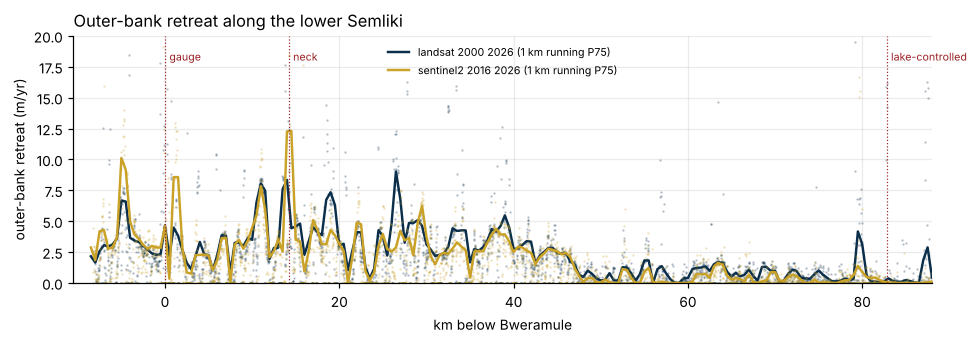

In [5]:
def outer_rates(R, kmax=88):
    k, v = [], []
    for r in R["transects"]:
        ob = r["outer_bank"]; x = r[ob + "_rate"]
        if x is None or r["km"] > kmax:
            continue
        k.append(r["km"]); v.append(max(x, 0.0))
    k, v = np.array(k), np.array(v); o = np.argsort(k)
    return k[o], v[o]

fig, ax = plt.subplots(figsize=(9, 3.2))
for name, col in (("landsat_2000_2026", "#0B2E4A"), ("sentinel2_2016_2026", "#C9A227")):
    k, v = outer_rates(RES[name])
    ax.plot(k, v, ".", ms=1.2, color=col, alpha=.25)
    cen = np.arange(-10, 88.5, .5)
    p75 = [np.percentile(v[(k >= c - .5) & (k < c + .5)], 75) if ((k >= c - .5) & (k < c + .5)).sum() > 5 else np.nan for c in cen]
    ax.plot(cen, p75, color=col, lw=1.6, label=name.replace("_", " ") + " (1 km running P75)")
for x_, lab in ((0, "gauge"), (14.2, "neck"), (82.8, "lake-controlled")):
    ax.axvline(x_, color="#9B2226", lw=.8, ls=":"); ax.text(x_ + .5, 18, lab, fontsize=7, color="#9B2226")
ax.set_ylim(0, 20); ax.set_xlim(-10.5, 88); ax.grid(alpha=.25)
ax.set_xlabel("km below Bweramule"); ax.set_ylabel("outer-bank retreat (m/yr)"); ax.legend(fontsize=7, frameon=False)
ax.set_title("Outer-bank retreat along the lower Semliki", loc="left")
fig.tight_layout(); fig.savefig(os.path.join(OUT, "retreat_along_river.png"), dpi=200); plt.show()

## 4  Rates by zone (report Section 6.2)

Two statistics per zone: the median rate of the outer banks that erode **significantly** (rate minus its 95 % interval above zero), and the 90th percentile of **all** outer-bank rates. Banks with fewer than 5 valid years are left out.

In [6]:
ZONES = [("10-0 km above the gauge", -10.5, 0), ("km 0-20", 0, 20), ("km 20-40", 20, 40), ("km 40-60", 40, 60), ("km 60-92", 60, 92.5)]

def zone_rates(R):
    out = []
    for zname, lo, hi in ZONES:
        v = []
        for r in R["transects"]:
            if not (lo <= r["km"] < hi):
                continue
            ob = r["outer_bank"]; rate = r[ob + "_rate"]; n = r[ob + "_n"]
            if rate is not None and n >= 5:
                v.append((max(rate, 0.0), r[ob + "_eroding"]))
        er = [x for x, e in v if e]
        out.append({"zone": zname, "n": len(v), "share_eroding": round(len(er) / max(len(v), 1), 2),
                    "median_eroding": round(float(np.median(er)), 2) if er else None,
                    "p90_all": round(float(np.percentile([x for x, _ in v], 90)), 2) if v else None})
    return out

ZR = {name: zone_rates(R) for name, R in RES.items()}
print("%-26s" % "zone" + "".join("%28s" % n for n in ZR))
for i, (zname, _, _) in enumerate(ZONES):
    print("%-26s" % zname + "".join("%15s / %-10s" % (ZR[n][i]["median_eroding"], ZR[n][i]["p90_all"]) for n in ZR))
print("(median of significantly eroding outer banks / 90th percentile of all outer banks, m per year)")

zone                                 landsat_2000_2026           landsat_2016_2026         sentinel2_2016_2026
10-0 km above the gauge              2.62 / 5.6                  3.59 / 7.72                 2.92 / 6.36      
km 0-20                              3.04 / 7.25                 3.33 / 5.45                  3.1 / 5.05      
km 20-40                             2.83 / 5.37                 3.27 / 4.44                 2.75 / 4.54      
km 40-60                             1.44 / 2.58                 2.69 / 2.96                 2.23 / 2.46      
km 60-92                             0.88 / 1.61                 2.12 / 1.82                 1.36 / 1.2       
(median of significantly eroding outer banks / 90th percentile of all outer banks, m per year)


## 5  Bends and setbacks (report Sections 6.3–6.4)

For each bend, the 90th percentile of its outer-bank rates (the *bend P90*) describes how fast its fastest part moves. The 50-year setback of a transect is

$$\text{setback}_{50} = 50 \times (\text{rate} + \text{CI}_{95}) + 2\,\sigma_{pos} + \text{bank allowance},\qquad \sigma_{pos}=\sqrt{(p/2)^2 + \text{registration}^2},$$

with a bank allowance of 4 m / tan(26.6°) = 8 m for a 4 m bank failing at 2H:1V.

In [7]:
def bend_summary(R, kmax=88):
    b = [x for x in R["bends"] if x["outer_rate_p90"] is not None and x["km_apex"] <= kmax]
    p90 = np.array([x["outer_rate_p90"] for x in b]); sb = np.array([x["setback_p90_m"] for x in b if x["setback_p90_m"] is not None])
    fast = sorted(b, key=lambda x: -x["outer_rate_p90"])[:6]
    return dict(n_bends=len(b), median_bend_p90=round(float(np.median(p90)), 2),
                setback_median=round(float(np.median(sb))), setback_p75=round(float(np.percentile(sb, 75))),
                setback_p90=round(float(np.percentile(sb, 90))),
                fastest=[(x["km_apex"], x["outer_rate_p90"]) for x in fast])
for name, R in RES.items():
    s = bend_summary(R)
    print(name)
    print("   %d bends; typical bend (median of bend P90) %.2f m/yr; 50-yr setback median / 75 %% / 90 %% of bends: %d / %d / %d m"
          % (s["n_bends"], s["median_bend_p90"], s["setback_median"], s["setback_p75"], s["setback_p90"]))
    print("   fastest bends (km, m/yr):", ", ".join("km %.1f %.1f" % f for f in s["fastest"]))

landsat_2000_2026
   118 bends; typical bend (median of bend P90) 2.32 m/yr; 50-yr setback median / 75 % / 90 % of bends: 205 / 358 / 592 m
   fastest bends (km, m/yr): km 18.5 13.4, km 27.8 13.1, km 14.1 12.6, km 32.0 11.8, km 26.6 11.2, km 0.3 10.9
landsat_2016_2026
   118 bends; typical bend (median of bend P90) 2.63 m/yr; 50-yr setback median / 75 % / 90 % of bends: 289 / 362 / 489 m
   fastest bends (km, m/yr): km 1.1 29.0, km 14.1 20.4, km -0.1 17.6, km -4.9 14.1, km 44.5 11.2, km 11.3 9.8
sentinel2_2016_2026
   118 bends; typical bend (median of bend P90) 2.17 m/yr; 50-yr setback median / 75 % / 90 % of bends: 220 / 302 / 418 m
   fastest bends (km, m/yr): km 14.1 18.4, km -4.9 13.2, km 1.1 12.3, km -0.1 12.3, km 11.3 9.4, km -5.5 9.2


## 6  Meander necks (report Section 7)

A neck is a pair of points close across land but far apart along the river. If both limbs keep retreating towards each other at their measured rates, the neck closes in about *neck width / (rate₁ + rate₂)* years.

In [8]:
R = RES["landsat_2000_2026"]
S = np.array([r["station_m"] for r in R["transects"]])
def rate_at(station, side_rates=("left", "right")):
    i = int(np.argmin(np.abs(S - station))); r = R["transects"][i]
    vals = [r[s + "_rate"] for s in side_rates if r[s + "_rate"] is not None]
    return max(vals) if vals else np.nan
for n in R["necks"]:
    r1, r2 = rate_at(n["upstream_station_m"]), rate_at(n["downstream_station_m"])
    t = n["neck_width_m"] / max(r1 + r2, 1e-6)
    print("neck at km %.1f: %d m across land, %d m along the river; limb rates %.1f and %.1f m/yr -> closes in about %.0f years if the rates hold"
          % (n["km"], n["neck_width_m"], n["bypassed_length_m"], r1, r2, t))

neck at km 14.2: 97 m across land, 1647 m along the river; limb rates 12.5 and 11.8 m/yr -> closes in about 4 years if the rates hold
neck at km 33.2: 144 m across land, 1558 m along the river; limb rates 4.7 and 0.1 m/yr -> closes in about 30 years if the rates hold


## 7  Check against the published results

The published tables of the report are in `data/results/`. With the published baseline, about 87 % of the individual bank rates are reproduced to within 0.005 m/yr; the rest differ because the published baseline coordinates are rounded to 0.1 m, which turns a few transects by a fraction of a degree and can make them pick up a neighbouring water body at their ends. Zone and bend statistics agree closely.

In [9]:
for name in RES:
    pubb = read_csv(os.path.join(DATA, "results", name, "bends.csv"))
    v_pub = [float(r["outer_rate_p90"]) for r in pubb if r["outer_rate_p90"] not in ("", "None")]
    v_new = [b["outer_rate_p90"] for b in RES[name]["bends"] if b["outer_rate_p90"] is not None]
    print("%-20s median bend P90: published %.2f, this run %.2f m/yr  (bends: %d / %d)"
          % (name, np.median(v_pub), np.median(v_new), len(v_pub), len(v_new)))

landsat_2000_2026    median bend P90: published 2.60, this run 2.60 m/yr  (bends: 139 / 129)
landsat_2016_2026    median bend P90: published 2.84, this run 2.97 m/yr  (bends: 139 / 129)
sentinel2_2016_2026  median bend P90: published 2.13, this run 2.22 m/yr  (bends: 139 / 129)
